# MODEL_BASELINE — Prédire le résultat d'un match de Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie modèle : Moussa

## La question (voir `PROJECT_CHARTER.md`)
Peut-on prédire le résultat d'un match de C1 **avant le coup d'envoi**, mieux qu'une règle simple ? Ce modèle servira ensuite à **simuler la saison 2026-2027** dans l'application.

| Élément | Notre choix |
|---|---|
| Une ligne | un match de Ligue des Champions (1 871 matchs, 2012-2026) |
| Cible | le résultat en **3 issues** : victoire domicile, nul, victoire extérieur. Le nul est une issue à part, pas une demi-victoire |
| Moment de la prédiction | juste avant le coup d'envoi : uniquement des informations connues à ce moment-là |
| Découpage | **dans le temps** : apprentissage 2012-2020, validation 2021-2022, **validation glissante sur 8 saisons (2015-2022)**, test final 2023-2025 |
| Baselines | `DummyClassifier` (toujours la classe la plus fréquente) et la règle « le meilleur Elo gagne » |
| Métriques | accuracy, **log loss** (qualité des probabilités), matrice de confusion |

## Plan
1. Charger la table et vérifier qu'elle est à jour
2. Variables autorisées et interdites
3. Le découpage dans le temps
4. Les baselines
5. Les modèles, comparés sur la validation
5 bis. La validation glissante sur 8 saisons : le vrai choix du modèle
6. Le test final, une seule fois
7. Matrice de confusion : et les nuls ?
8. Analyse de 3 erreurs
9. Le modèle final pour l'application
10. Conclusion et décision

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix
from xgboost import XGBClassifier

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, VERT, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad'
ISSUES = ['Victoire domicile', 'Nul', 'Victoire extérieur']   # l'ordre d'affichage
GRAINE = 42                                                    # pour que les résultats soient reproductibles

g = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig')
manquantes = {'resultat', 'ecart_elo_complet', 'attendu_domicile', 'neutre'} - set(g.columns)
assert not manquantes, (f"Colonnes absentes : {manquantes}. Relancez d'abord v2_elo.ipynb puis EDA_v2.ipynb "
                        "pour recréer output/eda_matchs_c1.csv avec l'Elo complet.")

# Jouer à domicile (1) ou sur terrain neutre (0, les finales)
g['domicile'] = (~g['neutre'].astype(bool)).astype(int)

print(f"Matchs : {len(g):,} | saisons {g['season'].min()} à {g['season'].max()}")
print("Répartition des résultats :")
print((g['resultat'].value_counts(normalize=True)[ISSUES] * 100).round(1).to_string())

Matchs : 1,871 | saisons 2012 à 2025
Répartition des résultats :
resultat
Victoire domicile     47.6
Nul                   20.0
Victoire extérieur    32.4


In [2]:
from sklearn.base import BaseEstimator, ClassifierMixin
from statsmodels.miscmodels.ordinal_model import OrderedModel

class LogistiqueOrdinale(BaseEstimator, ClassifierMixin):
    """Régression logistique ORDINALE : les 3 issues sont rangées dans un ordre
    (victoire extérieur < nul < victoire domicile). Le modèle calcule un seul « score de force » z
    à partir des variables, puis deux seuils découpent ce score en 3 issues."""
    ORDRE = ['Victoire extérieur', 'Nul', 'Victoire domicile']

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        rang = pd.Series(y).map({issue: i for i, issue in enumerate(self.ORDRE)}).to_numpy()
        ajustement = OrderedModel(rang, X, distr='logit').fit(method='bfgs', disp=False, maxiter=2000)
        k = X.shape[1]
        self.coef_ = ajustement.params[:k]                                                    # poids de chaque variable
        self.seuils_ = ajustement.model.transform_threshold_params(ajustement.params)[1:-1]   # les 2 seuils
        self.classes_ = np.array(sorted(self.ORDRE))                                          # même ordre que les autres modèles
        return self

    def predict_proba(self, X):
        z = np.asarray(X, dtype=float) @ self.coef_
        sous_le_seuil = lambda seuil: 1 / (1 + np.exp(-(seuil - z)))                         # P(issue <= seuil)
        p = {'Victoire extérieur': sous_le_seuil(self.seuils_[0]),
             'Nul': sous_le_seuil(self.seuils_[1]) - sous_le_seuil(self.seuils_[0]),
             'Victoire domicile': 1 - sous_le_seuil(self.seuils_[1])}
        return np.column_stack([p[issue] for issue in self.classes_])

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## 2. Variables autorisées et interdites

**La règle :** une variable n'est autorisée que si on la connaît **avant le coup d'envoi** (*« le saurais-je au moment d'utiliser le modèle ? »*).

| Groupe | Variables | Pourquoi |
|---|---|---|
| **Niveau (Elo)** | écart d'Elo complet, écart d'Elo C1 | calculés uniquement avec les matchs d'avant |
| **Terrain** | domicile ou terrain neutre | connu à l'avance |
| **Joueurs** | écart de valeur de l'effectif avant le match, âge moyen, rotation et meilleur buteur de la **saison précédente** | connus avant le match |
| **Fatigue** | écart de jours de repos, matchs joués sur 30 jours | calculés avec les matchs d'avant |
| ❌ **Interdites** | buts du match, résultat, surprise, tirs au but, affluence, nombre de compétitions de **toute** la saison | connus seulement pendant ou après le match : ce serait une **fuite d'information** |

On teste trois groupes de variables, du plus simple au plus complet. La cellule suivante **vérifie automatiquement** qu'aucune variable interdite ne s'est glissée dedans.

In [3]:
VARIABLES_ELO = ['ecart_elo_complet', 'domicile']
VARIABLES_ELO_PLUS = VARIABLES_ELO + ['ecart_log_valeur_effectif', 'ecart_elo_c1']
VARIABLES_TOUTES = VARIABLES_ELO_PLUS + ['ecart_age_moyen', 'ecart_rotation_championnat',
                                         'ecart_meilleur_buteur_championnat', 'ecart_jours_repos_borne', 'ecart_matchs_30j']

# Garde-fou : aucune variable qui contient le résultat ou le futur
INTERDITES = ['buts', 'goals', 'resultat', 'score', 'surprise', 'tirs_au_but', 'attendance', 'nb_competitions']
for variable in VARIABLES_TOUTES:
    assert not any(mot in variable for mot in INTERDITES), f"Variable interdite : {variable}"
print(f"{len(VARIABLES_TOUTES)} variables autorisées, aucune fuite détectée.")
g[VARIABLES_TOUTES].isna().sum().rename('valeurs manquantes').to_frame()

9 variables autorisées, aucune fuite détectée.


,valeurs manquantes
ecart_elo_complet,0
domicile,0
ecart_log_valeur_effectif,105
ecart_elo_c1,82
ecart_age_moyen,105
ecart_rotation_championnat,474
ecart_meilleur_buteur_championnat,474
ecart_jours_repos_borne,305
ecart_matchs_30j,305


## 3. Le découpage dans le temps

**Pourquoi pas un découpage au hasard ?** Nos matchs se suivent dans le temps. Mélanger au hasard reviendrait à apprendre sur des matchs de 2025 pour prédire des matchs de 2015 : le modèle connaîtrait l'avenir, et son score serait trop optimiste.

**On coupe donc en trois périodes :**

| Période | Saisons | Rôle |
|---|---|---|
| **Apprentissage** | 2012 à 2020 | le modèle apprend |
| **Validation** | 2021 et 2022 | on **compare** les modèles et on **choisit** le meilleur |
| **Test** | 2023 à 2025 | on mesure le modèle choisi **une seule fois**, à la fin |

**Pourquoi une validation en plus du test ?** Le prof l'a dit : *« le test final ne sert pas à choisir 25 variantes »*. Si on choisissait le modèle d'après le test, on finirait par choisir celui qui a eu de la chance sur ces matchs-là. Le test doit rester une surprise.

**Une précaution de plus :** les valeurs manquantes sont complétées (par la médiane) et les variables mises à l'échelle **dans un `Pipeline`**. Ces réglages sont calculés **uniquement sur l'apprentissage**, jamais sur les matchs à prédire.

In [4]:
apprentissage = g['season'] <= 2020
validation = g['season'].between(2021, 2022)
test = g['season'] >= 2023
assert not (apprentissage & validation).any() and not (validation & test).any()

repartition = pd.DataFrame({
    nom: (g.loc[masque, 'resultat'].value_counts(normalize=True)[ISSUES] * 100).round(1)
    for nom, masque in [('apprentissage', apprentissage), ('validation', validation), ('test', test)]
}).T
repartition.insert(0, 'matchs', [apprentissage.sum(), validation.sum(), test.sum()])
repartition

resultat,matchs,Victoire domicile,Nul,Victoire extérieur
apprentissage,1119,46.7,21.1,32.2
validation,250,46.8,20.8,32.4
test,502,50.0,17.1,32.9


## 4. Les baselines : les règles bêtes à battre

- **`DummyClassifier`** (la baseline du prof) : il prédit toujours la classe la plus fréquente, « victoire à domicile », et donne à chaque issue sa fréquence moyenne comme probabilité ;
- **la règle « le meilleur Elo gagne »** : elle prédit la victoire de l'équipe qui a le meilleur Elo complet (en comptant le bonus de 60 points à domicile). Elle ne donne **pas** de probabilités, donc pas de log loss.

**Comment lire les métriques :**
- **accuracy** : le pourcentage de matchs bien prédits ;
- **log loss** : la qualité des **probabilités**. Plus c'est bas, mieux c'est. Un modèle qui dirait « 1 chance sur 3 pour chaque issue » obtiendrait 1,099 : il faut faire nettement mieux. Cette mesure est essentielle pour nous, parce que la simulation de la saison utilisera les probabilités, pas seulement le vainqueur.

In [5]:
def resultats(y_vrai, y_predit, probas=None):
    # Accuracy et log loss (les colonnes de probabilités doivent suivre l'ordre alphabétique des classes)
    ligne = {'accuracy': accuracy_score(y_vrai, y_predit)}
    if probas is not None:
        ordre = sorted(ISSUES)
        ligne['log loss'] = log_loss(y_vrai, probas[ordre].to_numpy(), labels=ordre)
    ligne['% de nuls prédits'] = (pd.Series(y_predit) == 'Nul').mean()
    return ligne

def regle_elo(masque):
    return np.where(g.loc[masque, 'attendu_domicile'] > 0.5, 'Victoire domicile', 'Victoire extérieur')

def dummy(masque_appr, masque_eval):
    d = DummyClassifier(strategy='prior').fit(g.loc[masque_appr, VARIABLES_ELO], g.loc[masque_appr, 'resultat'])
    probas = pd.DataFrame(d.predict_proba(g.loc[masque_eval, VARIABLES_ELO]), columns=d.classes_)
    return d.predict(g.loc[masque_eval, VARIABLES_ELO]), probas

pred_dummy, proba_dummy = dummy(apprentissage, validation)
baselines_validation = pd.DataFrame({
    'Dummy (toujours « victoire domicile »)': resultats(g.loc[validation, 'resultat'], pred_dummy, proba_dummy),
    'Règle « meilleur Elo gagne »': resultats(g.loc[validation, 'resultat'], regle_elo(validation)),
}).T
baselines_validation.style.format({'accuracy': '{:.1%}', 'log loss': '{:.3f}', '% de nuls prédits': '{:.1%}'}, na_rep='—')

,accuracy,log loss,% de nuls prédits
Dummy (toujours « victoire domicile »),46.8%,1.047,0.0%
Règle « meilleur Elo gagne »,58.8%,—,0.0%


## 5. Les modèles, comparés sur la validation

On compare 6 modèles, du plus simple au plus complexe :

| Modèle | Variables | Idée |
|---|---|---|
| Régression logistique « Elo » | Elo complet + domicile | le plus simple : transforme l'écart d'Elo en 3 probabilités |
| **Régression logistique ordinale « Elo »** | Elo complet + domicile | la même, mais elle sait que les issues sont **dans un ordre** : défaite < nul < victoire |
| Régression logistique « Elo + » | + valeur de l'effectif + Elo C1 | les deux autres variables les plus liées au résultat |
| Régression logistique « toutes » | les 9 variables | tout ce qu'on a |
| Random Forest | les 9 variables | des centaines d'arbres de décision, qui peuvent trouver des effets non linéaires |
| XGBoost | les 9 variables | des arbres construits les uns après les autres pour corriger les erreurs des précédents |

**Pourquoi une version « ordinale » ?** La logistique classique traite les 3 issues comme 3 catégories sans rapport, comme « rouge, vert, bleu ». Or un match a un **ordre naturel** : le nul est vraiment **entre** la défaite et la victoire. La version ordinale calcule un seul **score de force** à partir de l'écart d'Elo, puis le coupe avec **deux seuils** : sous le 1er seuil, victoire extérieur ; entre les deux, nul ; au-dessus du 2e, victoire domicile. C'est la même idée que dans l'EDA, où on avait traité le résultat comme ordonné (corrélation de Spearman).

Chaque modèle apprend sur 2012-2020 et est évalué sur 2021-2022. **On choisit d'après la log loss**, parce que c'est la qualité des probabilités qui compte pour la simulation.

In [6]:
def creer_modeles():
    preparation = lambda: [SimpleImputer(strategy='median'), StandardScaler()]
    return {
        'Logistique « Elo »': (make_pipeline(*preparation(), LogisticRegression(max_iter=1000)), VARIABLES_ELO),
        'Logistique ordinale « Elo »': (make_pipeline(*preparation(), LogistiqueOrdinale()), VARIABLES_ELO),
        'Logistique « Elo + »': (make_pipeline(*preparation(), LogisticRegression(max_iter=1000)), VARIABLES_ELO_PLUS),
        'Logistique « toutes »': (make_pipeline(*preparation(), LogisticRegression(max_iter=1000)), VARIABLES_TOUTES),
        'Random Forest': (make_pipeline(SimpleImputer(strategy='median'),
                                        RandomForestClassifier(n_estimators=500, min_samples_leaf=30, random_state=GRAINE)),
                          VARIABLES_TOUTES),
        'XGBoost': (XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.03, subsample=0.8,
                                  random_state=GRAINE, eval_metric='mlogloss'), VARIABLES_TOUTES),
    }

CODES = {issue: i for i, issue in enumerate(sorted(ISSUES))}       # XGBoost veut des classes numérotées

def entrainer_et_predire(modele, variables, masque_appr, masque_eval):
    X_appr, y_appr = g.loc[masque_appr, variables], g.loc[masque_appr, 'resultat']
    X_eval = g.loc[masque_eval, variables]
    if isinstance(modele, XGBClassifier):
        modele.fit(X_appr, y_appr.map(CODES))
        probas = pd.DataFrame(modele.predict_proba(X_eval), columns=sorted(ISSUES))
    else:
        modele.fit(X_appr, y_appr)
        probas = pd.DataFrame(modele.predict_proba(X_eval), columns=modele.classes_)
    return probas.idxmax(axis=1).to_numpy(), probas

comparaison_validation = {}
for nom, (modele, variables) in creer_modeles().items():
    predit, probas = entrainer_et_predire(modele, variables, apprentissage, validation)
    comparaison_validation[nom] = resultats(g.loc[validation, 'resultat'], predit, probas)
comparaison_validation = pd.concat([baselines_validation, pd.DataFrame(comparaison_validation).T])
comparaison_validation.style.format({'accuracy': '{:.1%}', 'log loss': '{:.3f}', '% de nuls prédits': '{:.1%}'}, na_rep='—')

,accuracy,log loss,% de nuls prédits
Dummy (toujours « victoire domicile »),46.8%,1.047,0.0%
Règle « meilleur Elo gagne »,58.8%,—,0.0%
Logistique « Elo »,58.4%,0.907,0.0%
Logistique ordinale « Elo »,58.8%,0.910,0.0%
Logistique « Elo + »,59.2%,0.908,0.0%
Logistique « toutes »,59.6%,0.920,0.0%
Random Forest,58.0%,0.918,0.0%
XGBoost,59.6%,0.919,1.2%


**Lecture :**

| Sur la validation (2021-2022, 250 matchs) | Accuracy | Log loss |
|---|---|---|
| Dummy | 46,8 % | 1,047 |
| Règle « meilleur Elo gagne » | 58,8 % | — |
| Logistique « Elo » | 58,4 % | **0,907** |
| Logistique ordinale « Elo » | 58,8 % | 0,910 |
| Logistique « Elo + » | 59,2 % | 0,908 |
| Logistique « toutes » | 59,6 % | 0,920 |
| Random Forest | 58,0 % | 0,918 |
| XGBoost | 59,6 % | 0,919 |

- **Tous les modèles battent nettement le Dummy** : environ 58-60 % contre 47 %, et une log loss autour de 0,91 contre 1,05.
- **Les modèles à 9 variables font moins bien** (0,92) : ils apprennent du « bruit » propre aux matchs d'apprentissage. C'est le **surapprentissage**.
- **Les trois logistiques à 2-4 variables sont dans un mouchoir de poche** (0,907 à 0,910). Les départager sur seulement 250 matchs, c'est risqué : sur une seule période, la chance peut décider. Les écarts d'accuracy (58 à 60 %) sont d'ailleurs **plus petits que la marge d'erreur** (environ ± 6 points).

**On ne choisit donc pas encore.** La section suivante refait la comparaison sur **8 saisons** au lieu d'une seule période.

## 5 bis. La validation glissante sur 8 saisons : le vrai choix du modèle

**Le problème :** une seule validation de 250 matchs, c'est comme juger un élève sur un seul examen. Il a pu tomber sur un sujet facile, ou difficile.

**La solution : la validation glissante.** On fait passer **8 examens** au modèle, un par saison, de 2015 à 2022. À chaque fois, il n'apprend que sur les saisons **d'avant** :

| Examen | Le modèle apprend sur… | Il prédit… |
|---|---|---|
| 1 | 2012 à 2014 | la saison 2015 |
| 2 | 2012 à 2015 | la saison 2016 |
| … | … | … |
| 8 | 2012 à 2021 | la saison 2022 |

**Les deux règles restent respectées :**
- **jamais de futur** : chaque saison est prédite avec uniquement les saisons d'avant ;
- **le test 2023-2025 reste intact** : on ne s'en sert toujours qu'une fois, à la fin.

On choisit le modèle qui a **la meilleure log loss moyenne sur les 994 matchs** de ces 8 saisons.

Validation glissante : 8 saisons, 994 matchs


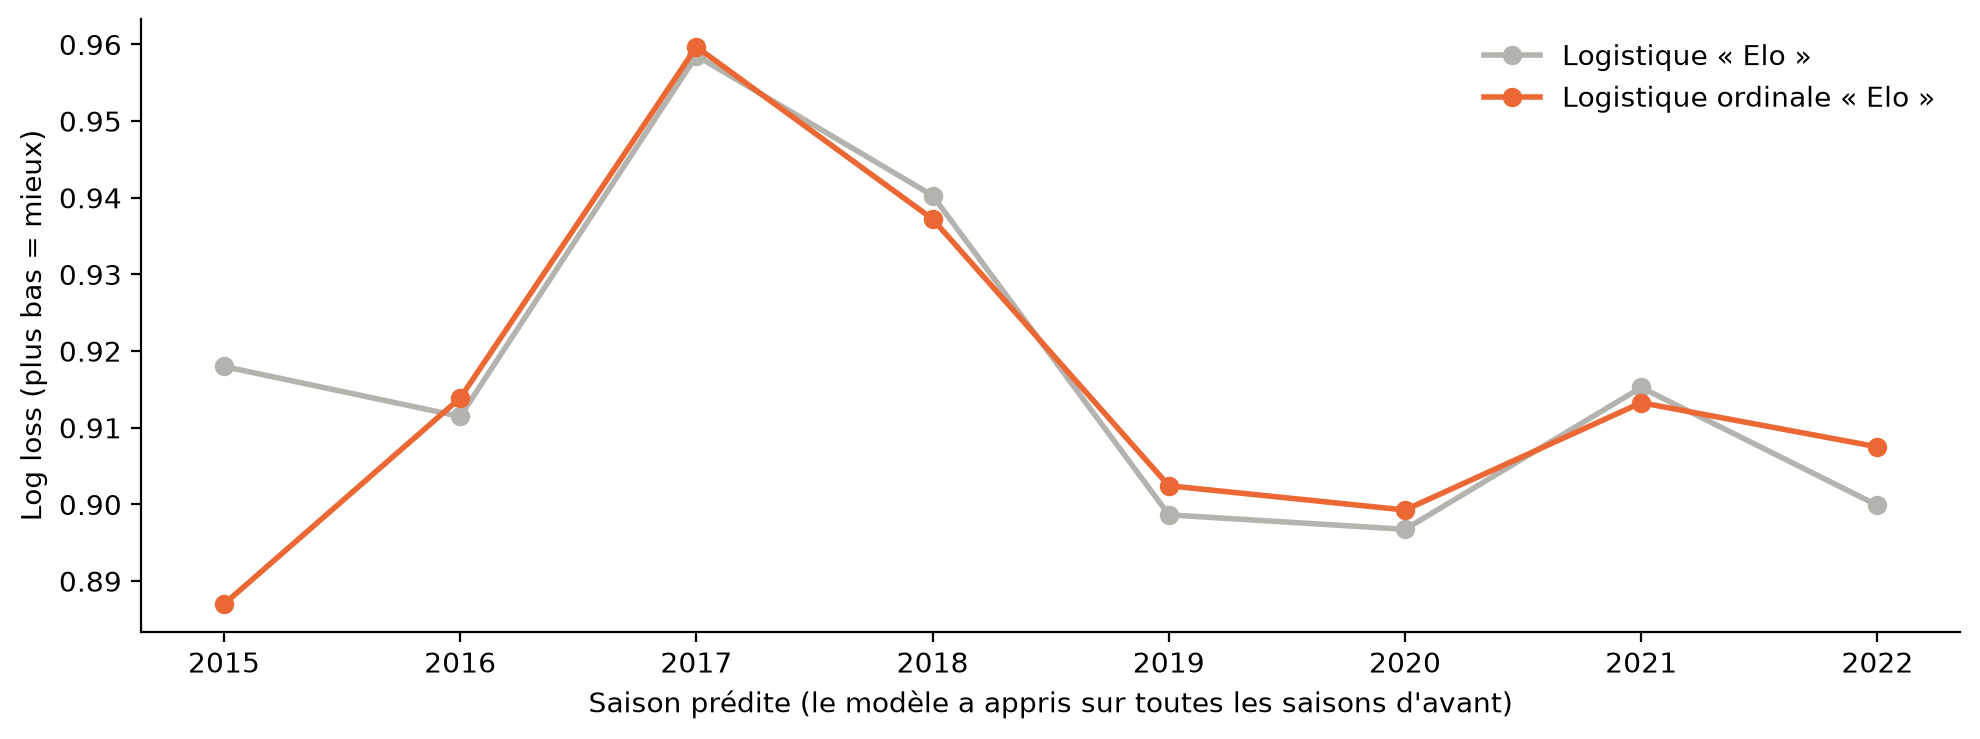

,log loss,accuracy,saisons où il bat la logistique « Elo »
Logistique ordinale « Elo »,0.9151,59.3%,3 / 8
Logistique « Elo »,0.9175,59.4%,0 / 8
Logistique « Elo + »,0.9191,59.0%,3 / 8
Random Forest,0.9240,58.8%,1 / 8
Logistique « toutes »,0.9324,58.4%,1 / 8
XGBoost,0.9480,58.5%,1 / 8


In [7]:
SAISONS_VALIDATION = range(2015, 2023)        # 8 saisons, toutes AVANT le test (2023-2025 reste intact)

def validation_glissante(nom):
    # Pour chaque saison : le modèle apprend sur toutes les saisons d'avant, puis prédit cette saison-là
    lignes = []
    for saison in SAISONS_VALIDATION:
        appr, a_predire = g['season'] < saison, g['season'] == saison
        modele, variables = creer_modeles()[nom]
        predit, probas = entrainer_et_predire(modele, variables, appr, a_predire)
        ligne = resultats(g.loc[a_predire, 'resultat'], predit, probas)
        lignes.append({'saison': saison, 'matchs': a_predire.sum(), **ligne})
    return pd.DataFrame(lignes).set_index('saison')

par_saison = {nom: validation_glissante(nom) for nom in creer_modeles()}
reference = par_saison['Logistique « Elo »']['log loss']
glissante = pd.DataFrame({
    nom: {'log loss': np.average(t['log loss'], weights=t['matchs']),
          'accuracy': np.average(t['accuracy'], weights=t['matchs']),
          'saisons où il bat la logistique « Elo »': f"{(t['log loss'] < reference - 1e-9).sum()} / {len(t)}"}
    for nom, t in par_saison.items()
}).T.sort_values('log loss')
print(f"Validation glissante : {len(SAISONS_VALIDATION)} saisons, {par_saison['Logistique « Elo »']['matchs'].sum()} matchs")

# Graphique : la log loss saison par saison des deux logistiques
fig, ax = plt.subplots(figsize=(10, 3.8))
for nom, couleur in [('Logistique « Elo »', GRIS), ('Logistique ordinale « Elo »', ORANGE)]:
    ax.plot(list(SAISONS_VALIDATION), par_saison[nom]['log loss'], marker='o', color=couleur, linewidth=2, label=nom)
ax.set_xlabel("Saison prédite (le modèle a appris sur toutes les saisons d'avant)")
ax.set_ylabel('Log loss (plus bas = mieux)')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
glissante.style.format({'log loss': '{:.4f}', 'accuracy': '{:.1%}'})

**Lecture et choix :**

| Validation glissante (8 saisons, 994 matchs) | Log loss moyenne | Accuracy | Saisons où il bat la logistique « Elo » |
|---|---|---|---|
| **Logistique ordinale « Elo »** | **0,9151** | 59,3 % | 3 / 8 |
| Logistique « Elo » | 0,9175 | 59,4 % | — |
| Logistique « Elo + » | 0,9191 | 59,0 % | 3 / 8 |
| Random Forest | 0,9240 | 58,8 % | 1 / 8 |
| Logistique « toutes » | 0,9324 | 58,4 % | 1 / 8 |
| XGBoost | 0,9480 | 58,5 % | 1 / 8 |

- **Le classement change par rapport à la validation unique.** Sur 2021-2022 seul, la version ordinale paraissait moins bonne (0,910 contre 0,907). Sur 8 saisons, c'est **la meilleure**. C'est exactement le risque qu'on voulait éviter : choisir sur une seule période, c'est en partie choisir au hasard.
- **Les modèles complexes confirment leur surapprentissage** : XGBoost et la logistique à 9 variables sont les derniers. XGBoost souffre surtout des premières saisons, où il a peu de matchs pour apprendre.
- **Soyons honnêtes sur l'écart (voir le graphique) :** l'ordinale gagne **en moyenne**, mais seulement sur 3 saisons sur 8. Son avance vient surtout de **2015**, la saison où le modèle n'avait que 3 saisons (2012-2014) pour apprendre : 0,887 contre 0,918. Sur les saisons récentes, les deux modèles sont **à égalité**, et la logistique classique est même un peu meilleure certaines années.
- **Pourquoi l'ordinale résiste mieux quand il y a peu de matchs ?** Elle a **moins de réglages à apprendre** : 2 poids et 2 seuils, contre 6 nombres pour la logistique classique, qui apprend une équation séparée pour chaque issue. Moins de réglages, c'est moins de risque d'apprendre du bruit. C'est la même leçon que les modèles à 9 variables, en plus petit.

**Choix : la régression logistique ordinale « Elo »** (écart d'Elo complet + domicile), en sachant que les deux logistiques **se valent presque**. Trois raisons :
1. c'est la **meilleure log loss** sur 8 saisons, le critère qu'on avait fixé à l'avance ;
2. elle est **aussi simple** que la logistique classique, avec même moins de réglages ;
3. elle **respecte l'ordre** des issues, ce qui a du sens en football : on le vérifie sur les nuls en section 7.

## 6. Le test final, une seule fois

Le modèle choisi en section 5 bis est maintenant entraîné sur **toutes** les saisons d'avant le test (2012-2022), puis évalué sur les 502 matchs de 2023 à 2025, qu'il n'a **jamais** vus. Pour la transparence, on affiche aussi les autres modèles, mais **le choix est déjà fait** : on ne le change pas d'après ces résultats.

Matchs de test : 502 | marge d'erreur d'une accuracy autour de 58 % : ± 4.3%


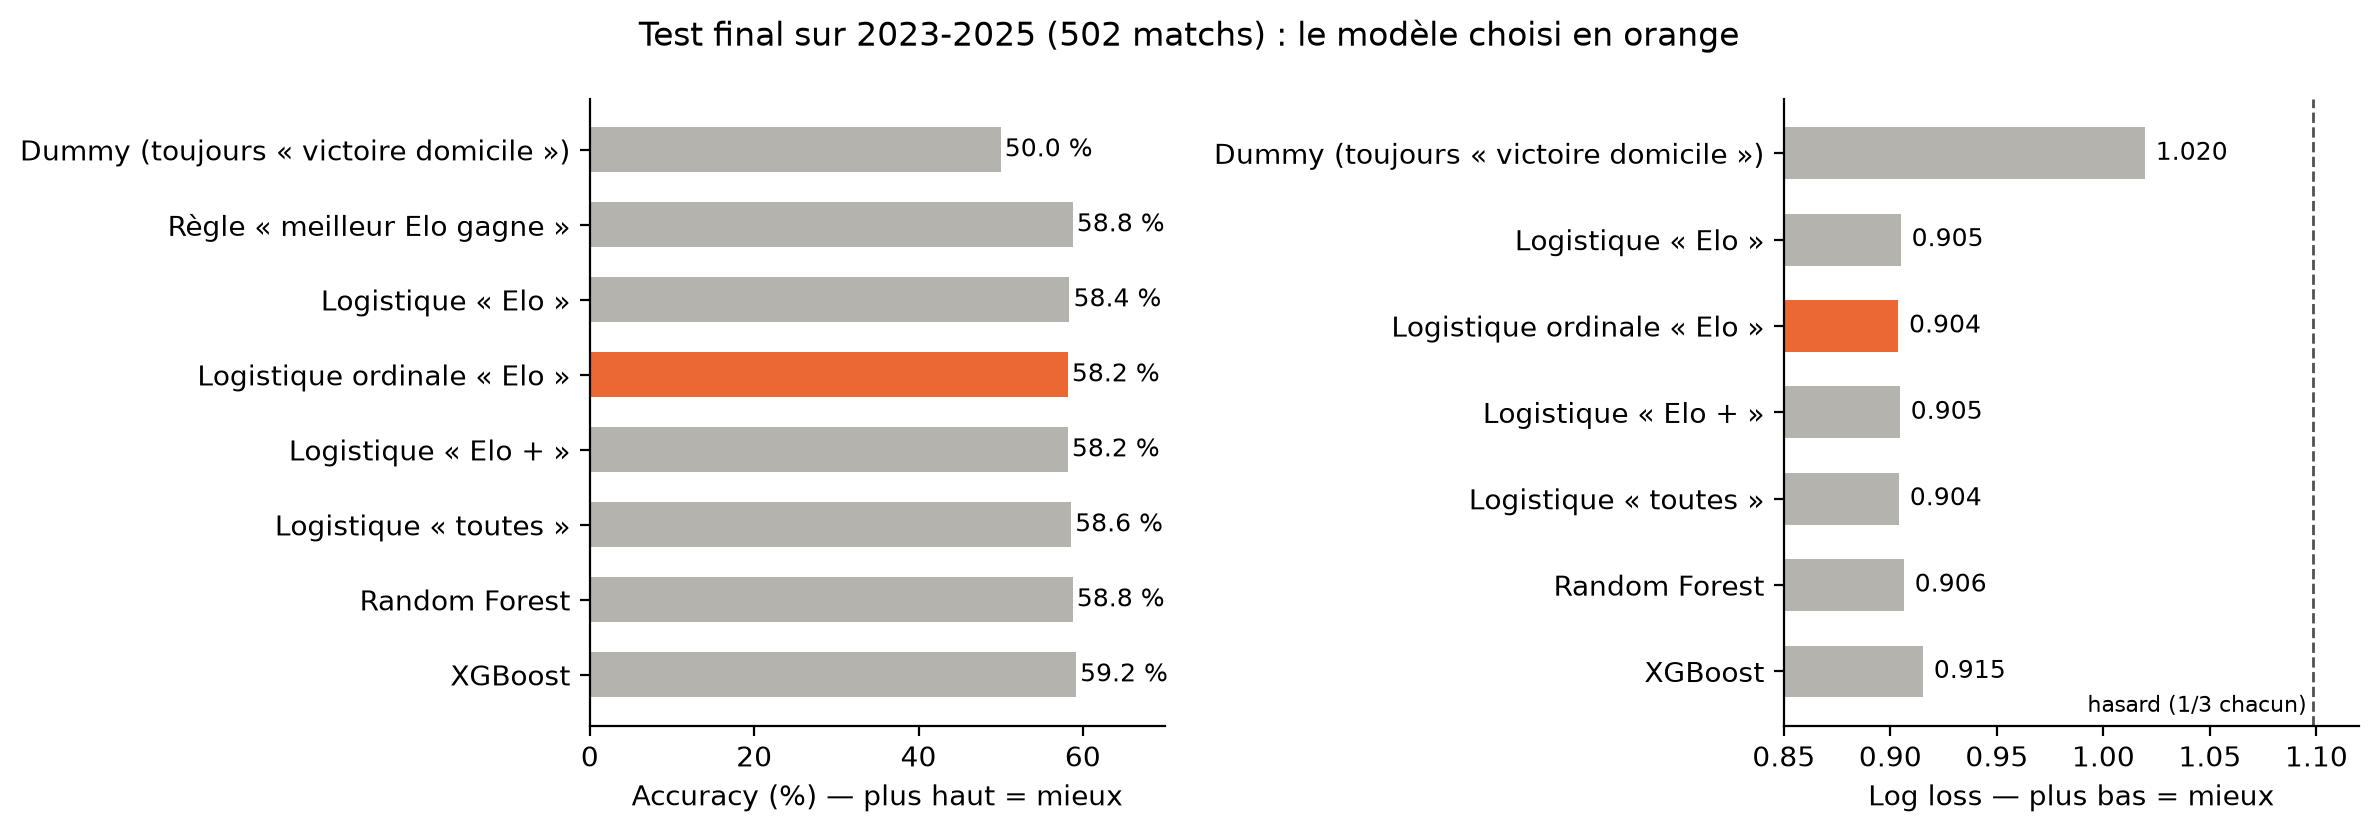

,accuracy,log loss,% de nuls prédits
Dummy (toujours « victoire domicile »),50.0%,1.020,0.0%
Règle « meilleur Elo gagne »,58.8%,—,0.0%
Logistique « Elo »,58.4%,0.905,0.0%
Logistique ordinale « Elo »,58.2%,0.904,0.0%
Logistique « Elo + »,58.2%,0.905,0.0%
Logistique « toutes »,58.6%,0.904,0.0%
Random Forest,58.8%,0.906,0.0%
XGBoost,59.2%,0.915,1.8%


In [8]:
MODELE_CHOISI = 'Logistique ordinale « Elo »'
avant_test = g['season'] <= 2022

pred_dummy_t, proba_dummy_t = dummy(avant_test, test)
comparaison_test = {
    'Dummy (toujours « victoire domicile »)': resultats(g.loc[test, 'resultat'], pred_dummy_t, proba_dummy_t),
    'Règle « meilleur Elo gagne »': resultats(g.loc[test, 'resultat'], regle_elo(test)),
}
predictions_test = {}
for nom, (modele, variables) in creer_modeles().items():
    predit, probas = entrainer_et_predire(modele, variables, avant_test, test)
    comparaison_test[nom] = resultats(g.loc[test, 'resultat'], predit, probas)
    predictions_test[nom] = (predit, probas)
comparaison_test = pd.DataFrame(comparaison_test).T

# Marge d'erreur de l'accuracy : sur 502 matchs, un pourcentage est connu à environ ± 4 points près
n_test = test.sum()
marge = 1.96 * np.sqrt(0.58 * 0.42 / n_test)
print(f"Matchs de test : {n_test} | marge d'erreur d'une accuracy autour de 58 % : ± {marge:.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
noms = comparaison_test.index
couleurs = [ORANGE if n == MODELE_CHOISI else GRIS for n in noms]
ax1.barh(noms, comparaison_test['accuracy'] * 100, color=couleurs, height=0.6)
for y, v in enumerate(comparaison_test['accuracy'] * 100):
    ax1.text(v + 0.5, y, f"{v:.1f} %", va='center', fontsize=9)
ax1.set_xlim(0, 70)
ax1.set_xlabel('Accuracy (%) — plus haut = mieux')
ax1.invert_yaxis()
avec_proba = comparaison_test['log loss'].dropna()
ax2.barh(avec_proba.index, avec_proba, color=[ORANGE if n == MODELE_CHOISI else GRIS for n in avec_proba.index], height=0.6)
for y, v in enumerate(avec_proba):
    ax2.text(v + 0.005, y, f"{v:.3f}", va='center', fontsize=9)
ax2.axvline(np.log(3), color='#52514e', linestyle='--', linewidth=1)
ax2.text(np.log(3) - 0.003, len(avec_proba) - 0.6, 'hasard (1/3 chacun)', fontsize=8, va='center', ha='right')
ax2.set_xlim(0.85, 1.12)
ax2.set_xlabel('Log loss — plus bas = mieux')
ax2.invert_yaxis()
for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Test final sur 2023-2025 (502 matchs) : le modèle choisi en orange')
plt.tight_layout()
plt.show()
comparaison_test.style.format({'accuracy': '{:.1%}', 'log loss': '{:.3f}', '% de nuls prédits': '{:.1%}'}, na_rep='—')

**Lecture :**

| Sur le test (2023-2025, 502 matchs jamais vus) | Accuracy | Log loss |
|---|---|---|
| Dummy (toujours « victoire domicile ») | 50,0 % | 1,020 |
| Règle « meilleur Elo gagne » | 58,8 % | — |
| **Logistique ordinale « Elo » (modèle choisi)** | **58,2 %** | **0,904** (la meilleure) |
| Logistique « Elo » | 58,4 % | 0,905 |
| Les 4 autres modèles | 58,2 à 59,2 % | 0,904 à 0,915 |

- **Le modèle choisi bat nettement le Dummy** : 58,2 % contre 50,0 % de bonnes prédictions, et une log loss de 0,904 contre 1,020. Ses probabilités sont aussi bien meilleures que le hasard (1,099).
- **Le test confirme le choix de la validation glissante** : sur des matchs jamais vus, l'ordinale a la meilleure log loss de tous les modèles. L'écart avec la logistique classique reste petit (0,904 contre 0,905).
- **Il fait jeu égal avec la règle « meilleur Elo gagne »** en accuracy (58,2 % contre 58,8 %, soit 3 matchs d'écart sur 502), bien en dessous de la marge d'erreur (± 4,3 points).
- **Ce que le modèle apporte en plus de la règle : des probabilités**, pour les 3 issues, nul compris. C'est indispensable pour simuler une saison.
- **Les modèles plus riches ne font pas mieux** : la valeur de l'effectif n'ajoute pas d'information utile une fois l'Elo complet connu.

## 7. Matrice de confusion : et les nuls ?

**Le piège de l'accuracy (slide 15 du cours) :** 20 % des matchs sont nuls. Un modèle peut avoir une bonne accuracy tout en se trompant sur **tous** les nuls. La matrice de confusion montre, pour chaque vrai résultat (en ligne), ce que le modèle a prédit (en colonne).

Mais pour un modèle de **probabilités**, il faut aussi vérifier autre chose : même si le nul n'est presque jamais l'issue **la plus probable**, sa **probabilité** est-elle juste ? Le second tableau compare, par groupe d'écart d'Elo, la probabilité de nul donnée par le modèle et la vraie fréquence des nuls.

In [9]:
predit, probas = predictions_test[MODELE_CHOISI]
vrai = g.loc[test, 'resultat'].to_numpy()
matrice = pd.DataFrame(confusion_matrix(vrai, predit, labels=ISSUES),
                       index=[f'vrai : {i}' for i in ISSUES], columns=[f'prédit : {i}' for i in ISSUES])
print("Matrice de confusion (nombre de matchs, saisons de test) :")
display(matrice)

# La probabilité de nul est-elle juste ? Comparaison par groupe d'écart d'Elo complet
verif_nul = pd.DataFrame({
    'écart Elo': g.loc[test, 'ecart_elo_complet'].to_numpy(),
    'proba nul prédite': probas['Nul'].to_numpy(),
    'nul réel': (vrai == 'Nul'),
})
verif_nul['groupe'] = pd.cut(verif_nul['écart Elo'].abs(), [0, 100, 200, 300, 2000],
                             labels=['0-100', '100-200', '200-300', '300 et +'], include_lowest=True)
calibration_nul = verif_nul.groupby('groupe', observed=True).agg(
    matchs=('nul réel', 'size'),
    proba_nul_predite=('proba nul prédite', 'mean'),
    frequence_reelle_des_nuls=('nul réel', 'mean'),
)
calibration_nul.style.format({'proba_nul_predite': '{:.1%}', 'frequence_reelle_des_nuls': '{:.1%}'})

Matrice de confusion (nombre de matchs, saisons de test) :


,prédit : Victoire domicile,prédit : Nul,prédit : Victoire extérieur
vrai : Victoire domicile,206,0,45
vrai : Nul,59,0,27
vrai : Victoire extérieur,79,0,86


,matchs,proba_nul_predite,frequence_reelle_des_nuls
groupe,,,
0-100,215,25.2%,20.9%
100-200,158,22.3%,15.2%
200-300,82,18.1%,18.3%
300 et +,47,11.5%,4.3%


**Lecture :**

- **Le modèle ne prédit jamais le nul comme issue la plus probable** : 0 des 86 nuls du test. Ce n'est pas un bug. Même entre deux équipes de même niveau, la probabilité de nul plafonne vers 25 % (voir le graphique de la section 9), donc une victoire de l'un ou de l'autre reste toujours plus probable. C'est le piège de l'accuracy du cours : elle ne montre pas cette qualité-là.
- **La probabilité de nul, elle, a du sens** : elle baisse quand l'écart grandit, comme la vraie fréquence.

| Écart d'Elo | Matchs | Proba de nul : logistique classique | Proba de nul : **ordinale (choisie)** | Vraie fréquence des nuls |
|---|---|---|---|---|
| 0 à 100 points | 215 | 23,8 % | 25,2 % | 20,9 % |
| 100 à 200 | 158 | 22,1 % | 22,3 % | 15,2 % |
| 200 à 300 | 82 | 19,5 % | **18,1 %** | 18,3 % |
| Plus de 300 | 47 | 14,7 % | **11,5 %** | 4,3 % |

- **Ce que l'ordinale corrige :** dans les matchs déséquilibrés (plus de 200 points d'écart), elle donne **moins de chances au nul**, plus près de la réalité. C'est logique : quand une équipe est bien plus forte, son « score de force » est loin des deux seuils, et la zone du nul devient étroite.
- **⚠️ Limite :** le modèle **surestime encore les nuls** sur 2023-2025. Il a appris sur une période avec 21 % de nuls, alors qu'il n'y en a eu que 17 % en 2023-2025, notamment avec le nouveau format à 36 clubs, qui crée plus de matchs déséquilibrés. Entre équipes proches, l'ordinale surestime même un peu plus (25,2 % contre 23,8 %).

## 8. Analyse de 3 erreurs

On regarde les 3 erreurs les plus **franches** du modèle sur les saisons de test : les matchs où il était le plus sûr de lui… et s'est trompé. Le but n'est pas de « corriger » ces matchs, mais de comprendre **ce que le modèle ne voit pas**.

In [10]:
erreurs = g.loc[test, ['date', 'season', 'home_club_name', 'away_club_name', 'home_elo_complet', 'away_elo_complet',
                       'dom_j_buts_pour', 'ext_j_buts_pour', 'resultat']].copy()
erreurs['prédit'] = predit
erreurs['confiance'] = probas.max(axis=1).to_numpy()
erreurs['proba du vrai résultat'] = [probas.iloc[i][r] for i, r in enumerate(vrai)]
erreurs['score'] = erreurs['dom_j_buts_pour'].astype(int).astype(str) + '-' + erreurs['ext_j_buts_pour'].astype(int).astype(str)
pires = erreurs[erreurs['prédit'] != erreurs['resultat']].nlargest(3, 'confiance')
pires[['date', 'home_club_name', 'away_club_name', 'home_elo_complet', 'away_elo_complet', 'score',
       'prédit', 'confiance', 'proba du vrai résultat']].round({'home_elo_complet': 0, 'away_elo_complet': 0,
                                                              'confiance': 2, 'proba du vrai résultat': 2})

,date,home_club_name,away_club_name,home_elo_complet,away_elo_complet,score,prédit,confiance,proba du vrai résultat
1448,2023-11-29,Bayern Munich,FC Copenhagen,1990.0,1644.0,0-0,Victoire domicile,0.85,0.09
1687,2025-09-16,SL Benfica,Qarabağ FK,1791.0,1449.0,2-3,Victoire domicile,0.85,0.06
1837,2026-02-24,Inter Milan,Fotballklubben Bodø/Glimt,1952.0,1613.0,1-2,Victoire domicile,0.85,0.06


**Lecture :** 

| Match | Ce que disait le modèle | Ce qui s'est passé | Ce que le modèle ne pouvait pas savoir |
|---|---|---|---|
| **Bayern 0-0 Copenhague** (29 novembre 2023) | Victoire du Bayern à 85 % | Match nul | Le Bayern avait **gagné ses 4 premiers matchs** de groupe : il était déjà qualifié. Copenhague, lui, jouait sa qualification. Le modèle ne voit pas l'**enjeu** du match |
| **Benfica 2-3 Qarabağ** (16 septembre 2025) | Victoire de Benfica à 85 % | Victoire de Qarabağ | L'Elo de Qarabağ (1 449) était **estimé**, faute d'Elo officiel. Il était trop bas : Qarabağ a ensuite battu Copenhague et Francfort et fait nul contre Chelsea. C'est la **limite de nos Elo estimés** |
| **Inter 1-2 Bodø/Glimt** (24 février 2026) | Victoire de l'Inter à 84 % | Victoire de Bodø/Glimt | Bodø/Glimt avait battu Manchester City et l'Atlético, et gagné le match **aller** 3-1. Son Elo, surtout construit en championnat norvégien, ne reflétait pas sa forme européenne. Et le modèle ne connaît pas le **score de l'aller** |

**Ce que ces erreurs nous apprennent :** le modèle ne voit que l'écart d'Elo et le terrain. Il ignore l'**enjeu** (une équipe déjà qualifiée), le **contexte d'un match retour**, et l'**incertitude** des Elo estimés pour les clubs moins connus. Ce sont des pistes d'amélioration, mais aucune n'est disponible proprement dans nos données aujourd'hui.

## 9. Le modèle final pour l'application

Maintenant que le modèle est choisi et testé, on l'entraîne sur **toutes les saisons** (2012-2026), pour qu'il profite de tous les matchs, puis on le **sauvegarde** dans `output/modele_match.joblib`.

**Ce qu'on sauvegarde :** pas l'objet Python, mais ses **paramètres**, c'est-à-dire quelques nombres : les moyennes et écarts-types pour la mise à l'échelle, les 2 poids du score de force et les 2 seuils. Avec la petite fonction `probas_match`, l'application recalcule les 3 probabilités de n'importe quel match **sans avoir besoin de notre classe**. La cellule vérifie que cette fonction donne exactement les mêmes probabilités que le modèle.

Le graphique montre ce que le modèle a appris : les probabilités des 3 issues **selon l'écart d'Elo complet**, pour un match joué à domicile. Plus l'équipe à domicile a d'avance, plus sa victoire devient probable, et **le nul est le plus probable quand les deux équipes se valent**.

Modèle sauvegardé : output/modele_match.joblib


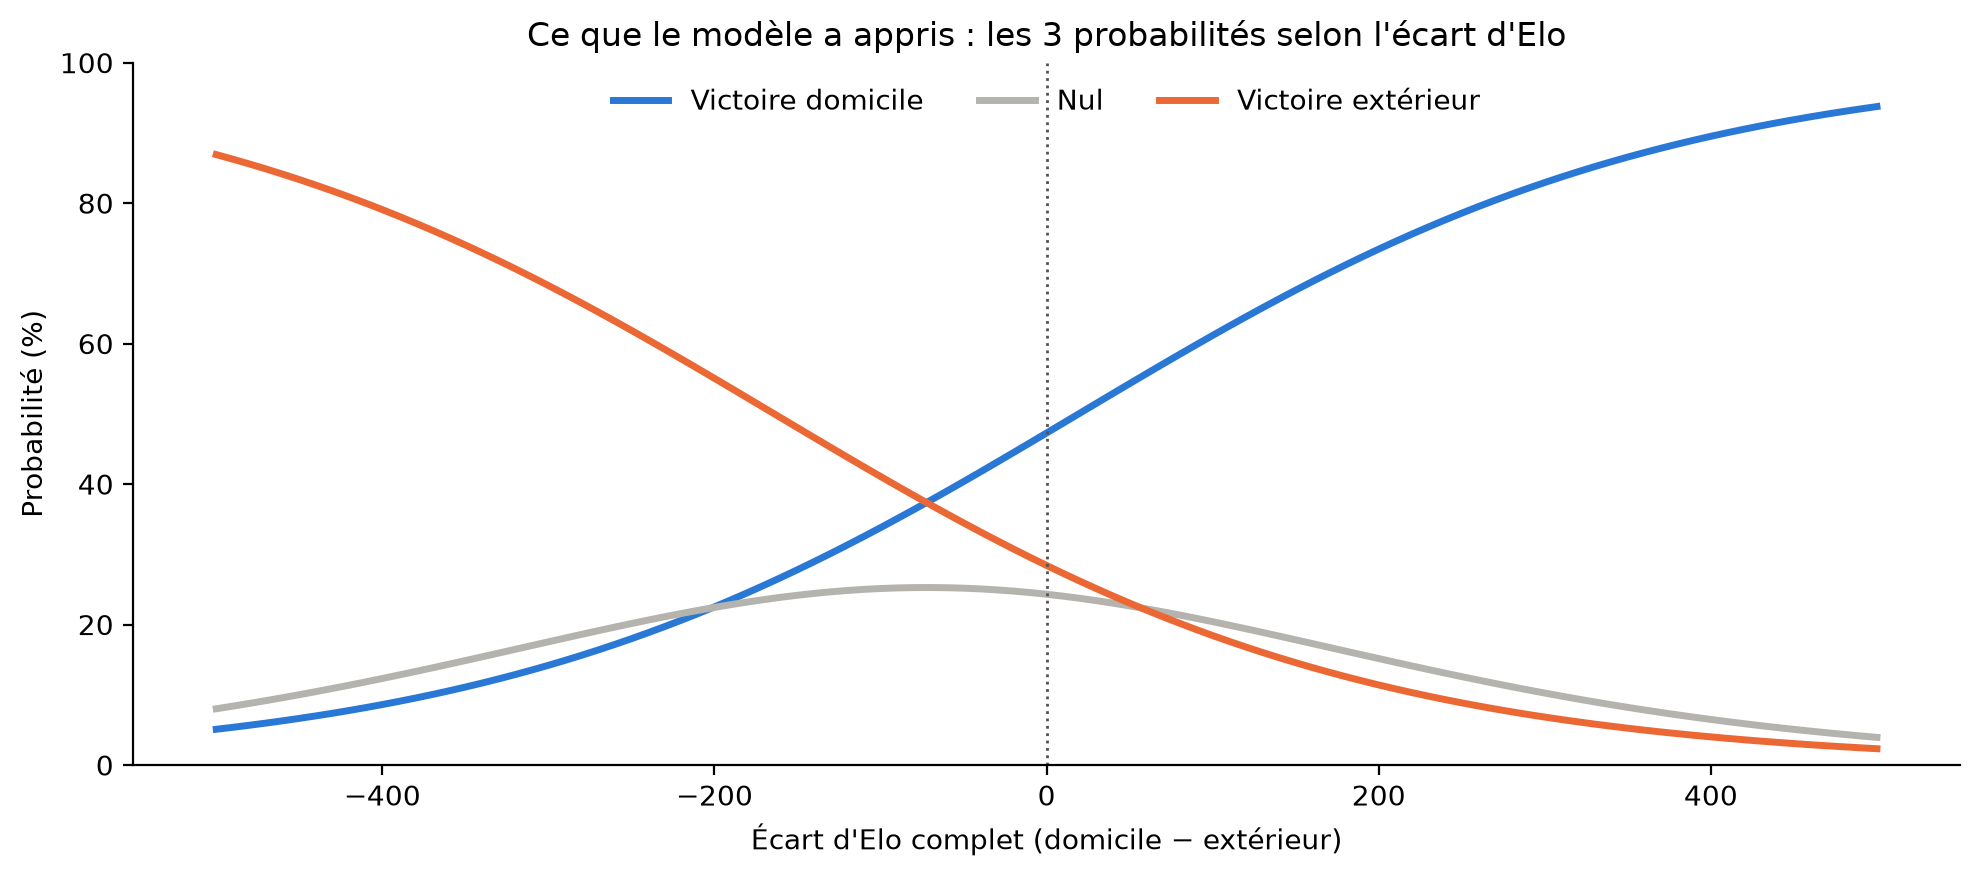

,Victoire domicile,Nul,Victoire extérieur
match,,,
Paris Saint-Germain – FC Barcelona,40.4,25.2,34.5
Bayern Munich – Arsenal FC,39.9,25.2,34.9
Manchester City – Paris Saint-Germain,56.9,21.9,21.2
Arsenal FC – Sabah FK,94.3,3.6,2.1


In [11]:
modele_final, variables_finales = creer_modeles()[MODELE_CHOISI]
modele_final.fit(g[variables_finales], g['resultat'])

# On sauvegarde les PARAMÈTRES du modèle (des nombres), pas l'objet Python :
# l'application n'aura pas besoin de connaître la classe LogistiqueOrdinale pour s'en servir.
echelle, ordinale = modele_final.named_steps['standardscaler'], modele_final.named_steps['logistiqueordinale']
parametres = {
    'type': 'logistique ordinale',
    'variables': variables_finales,
    'moyennes': echelle.mean_, 'ecarts_types': echelle.scale_,      # pour mettre les variables à l'échelle
    'coefs': ordinale.coef_, 'seuils': ordinale.seuils_,             # le score de force et ses 2 seuils
    'issues': ISSUES, 'bonus_domicile': 60,
    'entraine_sur': f"{g['season'].min()}-{g['season'].max()}",
}

def probas_match(parametres, ecart_elo, domicile=1):
    # Les 3 probabilités d'un match, uniquement avec les nombres sauvegardés (c'est cette fonction que l'appli copiera)
    x = (np.array([ecart_elo, domicile], dtype=float) - parametres['moyennes']) / parametres['ecarts_types']
    z = x @ parametres['coefs']
    sous = lambda seuil: 1 / (1 + np.exp(-(seuil - z)))
    s1, s2 = parametres['seuils']
    return {'Victoire domicile': 1 - sous(s2), 'Nul': sous(s2) - sous(s1), 'Victoire extérieur': sous(s1)}

# Vérification : la fonction donne exactement les mêmes probabilités que le modèle
verif = pd.DataFrame({'ecart_elo_complet': [250.0], 'domicile': [1]})
attendu = pd.DataFrame(modele_final.predict_proba(verif), columns=modele_final.classes_).iloc[0]
assert all(abs(probas_match(parametres, 250.0)[i] - attendu[i]) < 1e-9 for i in ISSUES)

os.makedirs('../output', exist_ok=True)
joblib.dump(parametres, '../output/modele_match.joblib')
print("Modèle sauvegardé : output/modele_match.joblib")

# Ce que le modèle a appris : probabilités selon l'écart d'Elo (match à domicile)
ecarts = np.arange(-500, 501, 10)
grille = pd.DataFrame({'ecart_elo_complet': ecarts, 'domicile': 1})[variables_finales]
p = pd.DataFrame(modele_final.predict_proba(grille), columns=modele_final.classes_)[ISSUES]

fig, ax = plt.subplots(figsize=(10, 4.5))
for issue, couleur in zip(ISSUES, [BLEU, GRIS, ORANGE]):
    ax.plot(ecarts, p[issue] * 100, color=couleur, linewidth=2.5, label=issue)
ax.axvline(0, color='#52514e', linewidth=1, linestyle=':')
ax.set_xlabel("Écart d'Elo complet (domicile − extérieur)")
ax.set_ylabel('Probabilité (%)')
ax.set_ylim(0, 100)
ax.set_title("Ce que le modèle a appris : les 3 probabilités selon l'écart d'Elo")
ax.legend(loc='upper center', ncol=3, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# Exemples : quelques affiches de la phase de ligue 2026-2027 (Elo complet avant le 8 septembre 2026)
participants = pd.read_csv('../output/elo_participants_2026.csv').set_index('club')['elo_complet']
def predire(domicile, exterieur):
    x = pd.DataFrame({'ecart_elo_complet': [participants[domicile] - participants[exterieur]], 'domicile': [1]})
    proba = pd.DataFrame(modele_final.predict_proba(x[variables_finales]), columns=modele_final.classes_)[ISSUES].iloc[0]
    return {'match': f'{domicile} – {exterieur}', **(proba * 100).round(1).to_dict()}
pd.DataFrame([predire('Paris Saint-Germain', 'FC Barcelona'), predire('Bayern Munich', 'Arsenal FC'),
              predire('Manchester City', 'Paris Saint-Germain'), predire('Arsenal FC', 'Sabah FK')]).set_index('match')

## 10. Conclusion et décision

### Résultats
- **Le modèle choisi**, une régression logistique **ordinale** avec l'écart d'Elo complet et le terrain, prédit **58,2 %** des matchs de test, contre **50,0 %** pour le `DummyClassifier`.
- **Il a été choisi par une validation glissante sur 8 saisons** (994 matchs), et non sur une seule période. Ça a changé le choix : sur 2021-2022 seul, on aurait pris la logistique classique.
- **Ses probabilités sont les meilleures de tous les modèles testés** : log loss de **0,904** sur le test, contre 1,020 pour le Dummy et 1,099 pour le hasard.
- **Il respecte l'ordre défaite < nul < victoire**, ce qui rend la probabilité de nul plus réaliste dans les matchs déséquilibrés.
- **Les modèles plus riches** (valeur de l'effectif, joueurs, fatigue, Random Forest, XGBoost) **ne font pas mieux**. Le niveau des équipes, résumé par l'Elo complet, contient presque toute l'information utile.

### Décision (section 8 du `PROJECT_CHARTER.md`)
Le modèle ne bat **pas nettement** la règle Elo en accuracy. Mais il apporte ce que la règle n'a pas : **une probabilité pour chacune des 3 issues, nul compris**. Pour simuler une saison entière, c'est indispensable. **On le garde donc pour la simulation et l'application**, en le présentant honnêtement : un modèle simple, aussi juste que la meilleure règle, mais qui donne des probabilités.

### Limites
- Le nul n'est jamais l'issue la plus probable, et sa probabilité reste surestimée sur 2023-2025 (17 % de nuls réels), surtout entre équipes proches.
- Le gain de l'ordinale sur la logistique classique est **petit** : meilleur en moyenne, mais sur 3 saisons de validation sur 8 seulement.
- Le modèle ignore l'enjeu du match, le contexte aller-retour, les blessures et la forme du moment.
- Les Elo estimés des petits clubs sont incertains (environ 40 à 60 points d'erreur).
- 502 matchs de test : une accuracy n'est connue qu'à ± 4 points près.

### La suite
1. **Simuler la saison 2026-2027** match par match, avec le calendrier officiel de Maxime et ce modèle, des milliers de fois, pour obtenir la **probabilité de titre** de chaque club.
2. **L'application** : elle chargera `output/modele_match.joblib` (les paramètres du modèle) et utilisera la fonction `probas_match` de la section 9 pour prédire n'importe quel match.